Medium artikel: https://medium.com/data-science/the-vehicle-routing-problem-exact-and-heuristic-solutions-c411c0f4d734
https://link.springer.com/content/pdf/10.1007/978-3-031-36805-9_17.pdf

In [26]:
import time
from itertools import cycle
import pandas as pd

import numpy as np
from scipy.spatial.distance import pdist, squareform
import matplotlib.pyplot as plt
import matplotlib as mpl
import networkx as nx
import pyomo.environ as pyo
from pyomo.contrib.appsi.solvers.highs import Highs



import matplotlib.pyplot as plt
import numpy as np

In [27]:
np.random.seed(42)  # Results should be always the same

N = 10
demands = np.random.randint(1, 10, size=N)
demands[0] = 0

capacity = 15
n_vehicles = 4

coordinates = np.random.rand(N, 2)
distances = squareform(pdist(coordinates, metric="euclidean"))
distances = np.round(distances, decimals=4)  # avoid numerical errors

In [28]:
distances.shape

(10, 10)

In [29]:
demands

array([0, 4, 8, 5, 7, 3, 7, 8, 5, 4])

In [30]:
coordinates

array([[1.42866818e-01, 6.50888473e-01],
       [5.64115790e-02, 7.21998772e-01],
       [9.38552709e-01, 7.78765841e-04],
       [9.92211559e-01, 6.17481510e-01],
       [6.11653160e-01, 7.06630522e-03],
       [2.30624250e-02, 5.24774660e-01],
       [3.99860972e-01, 4.66656632e-02],
       [9.73755519e-01, 2.32771340e-01],
       [9.06064345e-02, 6.18386009e-01],
       [3.82461991e-01, 9.83230886e-01]])

In [31]:
model = pyo.ConcreteModel()

In [32]:
model.V = pyo.Set(initialize=range(len(demands)))
model.A = pyo.Set(initialize=[(i, j) for i in model.V for j in model.V if i != j])
model.K = pyo.Set(initialize=range(n_vehicles))

In [33]:
model.Q = pyo.Param(initialize=capacity)
model.q = pyo.Param(model.V, initialize={i: d for (i, d) in enumerate(demands)})
model.c = pyo.Param(model.A, initialize={(i, j): distances[i, j] for (i, j) in model.A})

In [34]:
model.x = pyo.Var(model.A, model.K, within=pyo.Binary)
model.y = pyo.Var(model.V, model.K, within=pyo.Binary)

In [35]:
model.obj = pyo.Objective(
    expr=sum(
        model.x[i, j, k] * model.c[i, j]
        for (i, j) in model.A
        for k in model.K
    ),
    sense=pyo.minimize,
)

## Standaard VRP

In [13]:
# C2
def arcs_in(model, i):
    if i == model.V.first():
        return sum(model.x[:, i, :]) == len(model.K)
    else:
        return sum(model.x[:, i, :]) == 1.0

# C2
def arcs_out(model, i):
    if i == model.V.first():
        return sum(model.x[i, :, :]) == len(model.K)
    else:
        return sum(model.x[i, :, :]) == 1.0

# C3
def vehicle_assignment(model, i, k):
    return sum(model.x[:, i, k]) == model.y[i, k]

# C3
def comp_vehicle_assignment(model, i, k):
    return sum(model.x[i, :, k]) == model.y[i, k]

# C4 
def capacity_constraint(model, k):
    return sum(model.y[i, k] * model.q[i] for i in model.V) <= model.Q
    
# C6
def subtour_elimination(model, S, Sout, h, k):
    nodes_out = sum(model.x[i, j, k] for i in S for j in Sout)
    return model.y[h, k] <= nodes_out

In [14]:
model.arcs_in = pyo.Constraint(model.V, rule=arcs_in) # C2
model.arcs_out = pyo.Constraint(model.V, rule=arcs_out) # C2
model.vehicle_assignment = pyo.Constraint(model.V, model.K, rule=vehicle_assignment) # C3
model.comp_vehicle_assignment = pyo.Constraint(model.V, model.K, rule=comp_vehicle_assignment) # C3
model.capacity_constraint = pyo.Constraint(model.K, rule=capacity_constraint) # C4
model.subtour_elimination = pyo.ConstraintList() # C6

## SDVRP

In [36]:
# C2
def arcs_in(model, i):
    if i == model.V.first():
        return sum(model.x[:, i, :]) >= len(model.K)
    else:
        return sum(model.x[:, i, :]) >= 1.0

# C2
def arcs_out(model, i):
    if i == model.V.first():
        return sum(model.x[i, :, :]) >= len(model.K)
    else:
        return sum(model.x[i, :, :]) >= 1.0

# C3
def vehicle_assignment(model, i, k):
    return sum(model.x[:, i, k]) == sum(model.x[i, :, k])

# # C3
# def comp_vehicle_assignment(model, i, k):
#     return sum(model.x[i, :, k]) == model.y[i, k]



# C4 
def capacity_constraint(model, k):
    return sum(model.y[i, k] * model.q[i] for i in model.V) <= model.Q
    
# C6
def subtour_elimination(model, S, Sout, h, k):
    nodes_out = sum(model.x[i, j, k] for i in S for j in Sout)
    return model.y[h, k] <= nodes_out

In [37]:
model.arcs_in = pyo.Constraint(model.V, rule=arcs_in) # C2
model.arcs_out = pyo.Constraint(model.V, rule=arcs_out) # C2
model.vehicle_assignment = pyo.Constraint(model.V, model.K, rule=vehicle_assignment) # C3
# model.comp_vehicle_assignment = pyo.Constraint(model.V, model.K, rule=comp_vehicle_assignment) # C3
model.capacity_constraint = pyo.Constraint(model.K, rule=capacity_constraint) # C4
model.subtour_elimination = pyo.ConstraintList() # C6

In [38]:
def find_arcs(model):
    arcs = []
    for i, j in model.A:
        for k in model.K:
            if np.isclose(model.x[i, j, k].value, 1):
                arcs.append((i, j))
    return arcs

def find_subtours(arcs):
    G = nx.DiGraph(arcs)
    subtours = list(nx.strongly_connected_components(G))
    return subtours

In [39]:
def eliminate_subtours(model, subtours):
    proceed = False
    for S in subtours:
        if 0 not in S:
            proceed = True
            Sout = {i for i in model.V if i not in S}
            for h in S:
                for k in model.K:
                    model.subtour_elimination.add(
                      subtour_elimination(model, S, Sout, h, k)
                    )
    return proceed

In [48]:
def solve_step(model, solver):
    sol = solver.solve(model)
    print('sol klaar')
    arcs = find_arcs(model)
    print('arcs klaar')
    subtours = find_subtours(arcs)
    print('subtours klaar')
    proceed = eliminate_subtours(model, subtours)
    print('proceed klaar')
    return sol, proceed 


def solve(model, solver):
    proceed = True
    while proceed:
        sol, proceed = solve_step(model, solver)
    return sol

    

def solve(model, solver):
    proceed = True
    for i in range(10):
        sol, proceed = solve_step(model, solver)
    return sol

In [49]:
# from pyomo.__future__ import solver_factory
solver = Highs()
# solver = solver_factory("appsi_highs")
# solver = pyo.SolverFactory("appsi_highs").solve(model, tee=False)  # or "appsi_highs"
solver.highs_options = {
    "log_file": "Highs.log",
    "mip_heuristic_effort": 0.2,
    "mip_detect_symmetry": True,
    "mip_rel_gap": 1e-6,
}

solution = solve(model, solver)

sol klaar
arcs klaar
subtours klaar
proceed klaar
sol klaar
arcs klaar
subtours klaar
proceed klaar
sol klaar
arcs klaar
subtours klaar
proceed klaar
sol klaar
arcs klaar
subtours klaar
proceed klaar
sol klaar
arcs klaar
subtours klaar
proceed klaar
sol klaar
arcs klaar
subtours klaar
proceed klaar
sol klaar
arcs klaar
subtours klaar
proceed klaar
sol klaar
arcs klaar
subtours klaar
proceed klaar
sol klaar
arcs klaar
subtours klaar
proceed klaar
sol klaar
arcs klaar
subtours klaar
proceed klaar


In [43]:
for k in model.K:
    print(k)

0
1
2
3


In [57]:
for j in model.V:
    print(j)

0
1
2
3
4
5
6
7
8
9


In [52]:
def find_tours(model):
    tours = []
    for k in model.K:
        node = 0
        tours.append([0])
        while True:
            for j in model.V:
                if (node, j) in model.A:
                    if np.isclose(model.x[node, j, k].value, 1):
                        node = j
                        tours[-1].append(node)
                        break
            if node == 0:
                break
    return tours

In [53]:
solution.best_feasible_objective

3.1398

In [54]:
tours = find_tours(model)
print(tours)

[[0], [0], [0, 5, 0], [0, 1, 0]]


In [55]:
print(coordinates)
x, y = coordinates[:, 0], coordinates[:, 1] 

[[1.42866818e-01 6.50888473e-01]
 [5.64115790e-02 7.21998772e-01]
 [9.38552709e-01 7.78765841e-04]
 [9.92211559e-01 6.17481510e-01]
 [6.11653160e-01 7.06630522e-03]
 [2.30624250e-02 5.24774660e-01]
 [3.99860972e-01 4.66656632e-02]
 [9.73755519e-01 2.32771340e-01]
 [9.06064345e-02 6.18386009e-01]
 [3.82461991e-01 9.83230886e-01]]


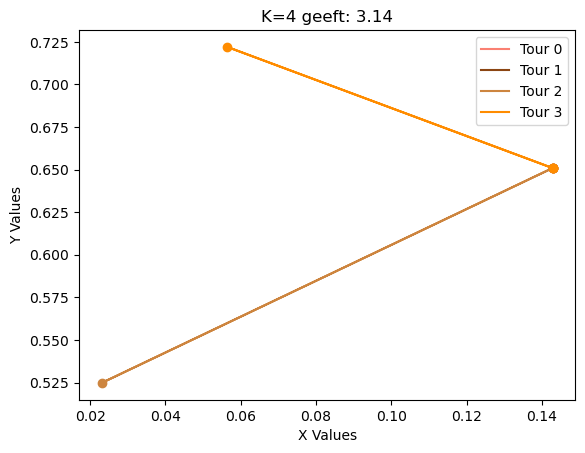

In [56]:
colours = [
    "darkslategray",
    "crimson",
    "salmon",
    "saddlebrown",
    "peru",
    "darkorange",
    "goldenrod",
    "khaki",
    "olivedrab",
    "mediumseagreen",
    "forestgreen",
    "teal",
    "cadetblue",
    "skyblue",
    "steelblue",
    "navy",
    "slateblue",
    "mediumpurple",
    "orchid",
    "palevioletred",
]

colours = colours[2:15]

for tour in range(len(tours)):
    tour_coordinates = coordinates[tours[tour]]
    x0, y0 = tour_coordinates[:, 0], tour_coordinates[:, 1]
    plt.scatter(x0, y0, color=colours[tour], zorder=2)
    plt.plot(x0, y0, color=colours[tour], label=f'Tour {tour}', zorder=1)

plt.title(f'K={n_vehicles} geeft: {round(solution.best_feasible_objective, 3)}')
plt.xlabel("X Values")
plt.ylabel("Y Values")
plt.legend()
plt.show() 